# ⚡ 05. Thuật toán FP-Growth & Khai phá Contrast Set (So sánh với Apriori)

**Thành viên thực hiện:** Thành viên 1 (ARM Lead)

Mục tiêu:
- Áp dụng thuật toán FP-Growth trên cùng dữ liệu.
- So sánh hiệu năng đối đầu trực tiếp: Thời gian thực thi & Bộ nhớ (Apriori vs FP-Growth).
- Khai phá Contrast Set (Tập tương phản): Tìm luật chỉ có ở trận Thắng mà KHÔNG có ở trận Thua.
- Khám phá 'Hidden Meta' (Tần suất thấp nhưng Lift và Confidence cực cao).

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from src.arm_miner import AssociationRuleMiner
import warnings
warnings.filterwarnings('ignore')

## 1. Nạp dữ liệu

In [2]:
bin_win = pd.read_pickle('../data/processed/bin_win.pkl')
bin_lose = pd.read_pickle('../data/processed/bin_lose.pkl')
miner = AssociationRuleMiner(min_support=0.03, min_confidence=0.5, min_lift=1.2)

## 2. Chạy FP-Growth

In [3]:
t0 = time.time()
frequent_itemsets_fp, rules_fp, timing_fp = miner.run_fpgrowth(bin_win, win_label=True)
fp_time = time.time() - t0

print(f'Thời gian chạy FP-Growth: {fp_time:.2f} giây')
print(f'Số tập mục phổ biến: {len(frequent_itemsets_fp)}')
print(f'Số luật kết hợp: {len(rules_fp)}')

Thời gian chạy FP-Growth: 19.02 giây
Số tập mục phổ biến: 13422
Số luật kết hợp: 16846


## 3. So sánh Hiệu năng Đối đầu (Apriori vs FP-Growth)

               Metric     Apriori   FP-Growth  Difference
0  Execution Time (s)      4.4378     18.4757     14.0379
1    Peak Memory (MB)    165.3200     28.2900   -137.0300
2   Frequent Itemsets  13422.0000  13422.0000      0.0000
3   Association Rules  16846.0000  16846.0000      0.0000


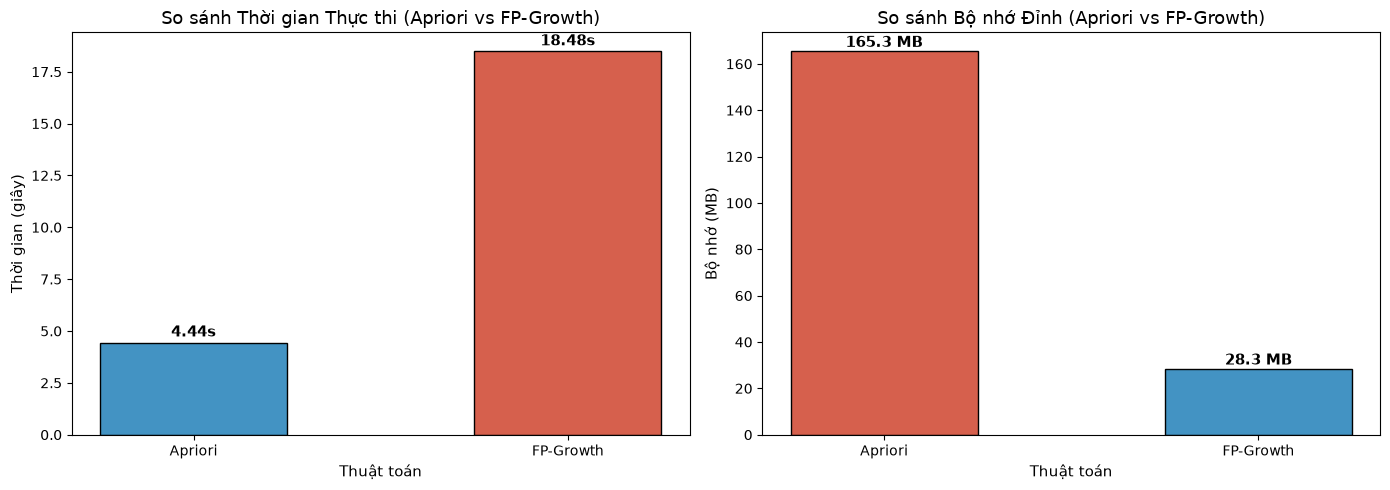

In [5]:
%matplotlib inline
import matplotlib.pyplot as plt

comp_df = miner.compare_algorithms(bin_win.sample(n=min(10000, len(bin_win)), random_state=42))
print(comp_df)

# --- So sánh Thời gian và Bộ nhớ ---
time_row = comp_df[comp_df["Metric"] == "Execution Time (s)"]
algorithms = ["Apriori", "FP-Growth"]
time_values = [float(time_row["Apriori"].values[0]), float(time_row["FP-Growth"].values[0])]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Thời gian
colors_time = ["#4393c3", "#d6604d"]
bars1 = axes[0].bar(algorithms, time_values, color=colors_time, edgecolor="black", width=0.5)
axes[0].set_title("So sánh Thời gian Thực thi (Apriori vs FP-Growth)", fontsize=13)
axes[0].set_ylabel("Thời gian (giây)", fontsize=11)
axes[0].set_xlabel("Thuật toán", fontsize=11)
for bar, val in zip(bars1, time_values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, f"{val:.2f}s", ha="center", fontsize=11, fontweight="bold")

# Biểu đồ 2: Bộ nhớ
mem_row = comp_df[comp_df["Metric"] == "Peak Memory (MB)"]
mem_values = [float(mem_row["Apriori"].values[0]), float(mem_row["FP-Growth"].values[0])]

colors_mem = ["#d6604d", "#4393c3"]
bars2 = axes[1].bar(algorithms, mem_values, color=colors_mem, edgecolor="black", width=0.5)
axes[1].set_title("So sánh Bộ nhớ Đỉnh (Apriori vs FP-Growth)", fontsize=13)
axes[1].set_ylabel("Bộ nhớ (MB)", fontsize=11)
axes[1].set_xlabel("Thuật toán", fontsize=11)
for bar, val in zip(bars2, mem_values):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, f"{val:.1f} MB", ha="center", fontsize=11, fontweight="bold")

plt.tight_layout()
plt.show()

## 4. Khai phá Tập Tương Phản (Contrast Set Mining: Win vs Lose)

In [ ]:
contrast_rules = miner.contrast_set_mining(bin_win, bin_lose)
print(f'Số luật đặc trưng thắng (Win-defining rules): {len(contrast_rules)}')
if not contrast_rules.empty:
    print(display(contrast_rules.head(10)))

Số luật đặc trưng thắng (Win-defining rules): 16325


,antecedents,consequents,win_support,win_confidence,win_lift,lose_support,lose_confidence,lose_lift,support_diff,confidence_diff,lift_diff
0,"frozenset({Item_GiantSlayer, Champ_Singed})",frozenset({Trait_Zaun_2}),0.0480,1.0,4.761905,0.0,0.0,0.0,0.0480,1.0,4.7619
1,"frozenset({Item_GiantSlayer, Champ_Singed})",frozenset({Item_InfinityEdge}),0.0480,1.0,1.550388,0.0,0.0,0.0,0.0480,1.0,1.5504
2,"frozenset({Item_GiantSlayer, Champ_Singed})",frozenset({Champ_Jinx}),0.0480,1.0,3.072197,0.0,0.0,0.0,0.0480,1.0,3.0722
3,"frozenset({Item_GiantSlayer, Champ_Singed})",frozenset({Champ_Warwick}),0.0480,1.0,3.154574,0.0,0.0,0.0,0.0480,1.0,3.1546
4,"frozenset({Item_GiantSlayer, Champ_Singed})",frozenset({Champ_Silco}),0.0480,1.0,4.192872,0.0,0.0,0.0,0.0480,1.0,4.1929
5,"frozenset({Item_GiantSlayer, Champ_Singed})",frozenset({Champ_Ekko}),0.0480,1.0,4.273504,0.0,0.0,0.0,0.0480,1.0,4.2735
6,"frozenset({Trait_Shurima_2, Champ_Ryze})",frozenset({Champ_Renekton}),0.0395,1.0,5.390836,0.0,0.0,0.0,0.0395,1.0,5.3908
7,frozenset({Trait_Shurima_2}),"frozenset({Champ_Renekton, Champ_Ryze})",0.0395,1.0,22.222222,0.0,0.0,0.0,0.0395,1.0,22.2222
8,"frozenset({Item_HandOfJustice, Trait_Shurima_2})",frozenset({Champ_Ryze}),0.0395,1.0,13.245033,0.0,0.0,0.0,0.0395,1.0,13.2450
9,"frozenset({Trait_Shurima_2, Champ_Ryze})",frozenset({Item_HandOfJustice}),0.0395,1.0,2.680965,0.0,0.0,0.0,0.0395,1.0,2.6810


None


## 5. Khai phá Hidden Meta (Luật ít người chơi nhưng tỷ lệ thắng đột biến)

In [ ]:
hidden_meta = miner.find_hidden_meta(rules_fp, max_support=0.06, min_lift=1.6, min_confidence=0.65)
print(f'Số tổ hợp Hidden Meta phát hiện được: {len(hidden_meta)}')
print(miner.format_rules(hidden_meta, top_n=10))

Số tổ hợp Hidden Meta phát hiện được: 4346
                               ASSOCIATION RULES                                
#    Antecedent -> Consequent                             Supp   Conf   Lift
--------------------------------------------------------------------------------
1    Champ_Azir, Champ_Ryze -> Trait_Shurima_2           0.040  1.000  25.32
2    Trait_Shurima_2 -> Champ_Azir, Champ_Ryze           0.040  1.000  25.32
3    Champ_Ryze, Champ_Taliyah -> Trait_Shurima_2        0.040  0.940  23.81
4    Trait_Shurima_2 -> Champ_Ryze, Champ_Taliyah        0.040  1.000  23.81
5    Trait_Shurima_2 -> Champ_Azir, Champ_Renekton       0.040  1.000  23.26
6    Champ_Azir, Champ_Renekton -> Trait_Shurima_2       0.040  0.919  23.26
7    Champ_Renekton, Champ_Taliyah -> Trait_Shurima_2    0.040  0.898  22.73
8    Trait_Shurima_2 -> Champ_Renekton, Champ_Taliyah    0.040  1.000  22.73
9    Champ_Azir, Champ_Taliyah -> Trait_Shurima_2        0.040  0.888  22.47
10   Trait_Shurima_2 -> C

## 6. Tổng kết phần ARM
- **FP-Growth** vượt trội hoàn toàn về tốc độ so với Apriori nhờ cấu trúc FP-Tree nén dữ liệu và không cần sinh ứng viên lặp đi lặp lại.
- **Contrast Set Mining** đã tách biệt thành công các tổ hợp tướng chỉ xuất hiện ở nhóm thắng.
- Đã phát hiện ra các cụm Hidden Meta tiềm năng.